# When does the AI coder pick its algorithm? An audit (demo of `eval.py`)

**Question behind the project.** How does "creativity" show up inside an open-weight LLM, and can it be steered? The test bed asks **Qwen3-8B** to *implement a path-search algorithm* and records which algorithm it writes:
- **T1**, unweighted grid path: the default is BFS.
- **T2**, weighted shortest path: the default is Dijkstra.

Six iteration-1 experiments generated about 20,000 programs. They varied the prompt (bans such as "do not use BFS", novelty instructions, context seeds), the decoding (temperature, top-k) and the activations (steering), and they saved residual-stream states.

**This artifact** is the round-one audit of those six experiments. It generates nothing, makes no LLM calls and costs $0. Its entry point `eval.py` first runs any of seven stage scripts whose output is missing:
- inventory of the inputs;
- locus probes (GPU);
- geometry sweep;
- tables;
- figures;
- two independent audits.

It then assembles their outputs into `eval_out.json` (80 headline metrics, 4 example datasets) and `corrections.json`.

**What this notebook runs.** It runs `eval.py`'s own assembly code, split into cells, with explanations between them. The only change is where the inputs come from. The stage outputs ship in `mini_demo_data.json`, which is loaded from GitHub with a local fallback. The bundle keeps every field `eval.py` reads, but only 100 of the 1,335 table rows: 40 perturbation conditions, 36 knobs and 24 probe cells. The notebook then:
- compares its metrics with the published ones;
- plots the key results, including the PCA of the saved hidden states.

Runtime is a few seconds after the install cell.

**Headline results of the audit**

| | T1 grid path (default BFS) | T2 weighted shortest path (default Dijkstra) |
|---|---|---|
| Where the within-ban choice is readable (0a) | **R**: the prompt-end state already reads it (balanced accuracy 0.855), and the within-paraphrase null absorbs every generated position. | **k_pre**: 0.762 at layer 8, +0.28 over R. It is only a **post-commit readout**: the written prefix alone gives 0.756 (`import heapq` vs `from collections import deque`). |
| What replaces the banned default (0d) | DFS, 116 of 128 compliant programs over 5 draws | BF_SPFA, 272 of 272 over 5 draws |
| Nearest survivor to the default's centroid (0b) | DFS at layers 25–28; the order flips at layer 24 | Floyd–Warshall in 100% of subsamples, never BF_SPFA |
| Diversity knobs (0d) | none reaches Hill-1 ≥ 2 at < 20 pass points | none |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (eval.py logs with loguru)
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

import argparse
import json
import math
import subprocess
import sys
import time

import numpy as np
import pandas as pd
from loguru import logger

# demo: `from common import HERE, RES, TAB, clean, jdump, setup_logging` is replaced by the common.py cell below
import io
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-2/evaluation-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# Until this notebook's own data file is pushed, the GitHub path may still serve an older demo bundle with a
# different layout; then use the copy of mini_demo_data.json that sits next to this notebook.
if "results" not in data and Path("mini_demo_data.json").exists():
    print("GitHub copy has an older layout, using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
print(data["description"])
print("stage outputs:", ", ".join(data["results"]))
print("curated table rows:", {k: len(v.splitlines()) - 1 for k, v in data["tables"].items()},
      "of", data["table_rows_in_original"])

GitHub copy has an older layout, using local mini_demo_data.json
Curated inputs of eval.py (round-one audit of six iteration-1 experiments on Qwen3-8B; T1 grid path, T2 weighted shortest path): stage outputs results/*.json, 100 curated rows of tables/*.csv, exp3/forks.json, and the published metrics_agg for comparison.
stage outputs: locus.json, geometry.json, tables.json, positioning.json, inventory.json, harmonise.json, figures.json, audit.json, audit_extra.json
curated table rows: {'perturbation_table.csv': 40, 'knob_table.csv': 36, 'locus_cells.csv': 24} of {'perturbation_table.csv': 249, 'knob_table.csv': 183, 'locus_cells.csv': 903}


## Configuration

`eval.py` has no epochs or sample counts. Its only flag is `--rerun`.

The quantity that scales in this demo is how many rows of the three stage tables flow through the assembly. Those rows become the `perturbation_table`, `knob_table` and `locus_cells` example datasets of `eval_out.json`. They also feed the knob summary and the row-count metrics.

The curated rows alternate T1/T2 in priority order, so even 2 rows cover both tasks. Every other metric comes from the stage summaries and does not depend on these caps.

In [5]:
# --- Config ---
# How many rows of each curated stage table the assembly reads (the first N; rows alternate T1/T2 by priority).
# mini_demo_data.json ships 40 / 36 / 24 curated rows. The original run read every row of the artifact's tables:
# N_PERTURBATION_ROWS = 249, N_KNOB_ROWS = 183, N_LOCUS_CELLS = 903
N_PERTURBATION_ROWS = 40
N_KNOB_ROWS = 36
N_LOCUS_CELLS = 24
# eval.py's only CLI flag: --rerun re-runs the seven stage scripts (~16 min incl. GPU probes on the saved Qwen3-8B
# states). Those scripts and their iteration-1 inputs are not part of this demo, so keep it False.
RERUN = False

## Helpers from `common.py`

`eval.py` imports six names from the artifact's `common.py`:
- the paths `HERE`, `RES` and `TAB`;
- the JSON helpers `clean` and `jdump`;
- `setup_logging`.

They are copied here unchanged, except that `HERE` is the notebook's working directory. That is where `eval_out.json`, `corrections.json` and `logs/eval.log` are written.

In [6]:
# --- from common.py: the paths and JSON helpers that eval.py imports (functions copied verbatim) ---
HERE = Path.cwd()  # original: Path(__file__).resolve().parent, the artifact folder; eval.py writes its outputs here
RES = HERE / "results"
TAB = HERE / "tables"
LOG = HERE / "logs"
LOG.mkdir(exist_ok=True)  # original: mkdir of results/, tables/, figures/ and logs/; the demo writes only logs/


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(LOG / f"{name}.log", rotation="30 MB", level="DEBUG")


def jdump(obj: Any, p: Path) -> None:
    p.write_text(json.dumps(obj, indent=1, default=_json_default))


def _json_default(o: Any) -> Any:
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, set):
        return sorted(o)
    raise TypeError(f"not serialisable: {type(o)}")


def clean(o: Any) -> Any:
    """Recursively replace NaN/inf by None so the JSON is strict."""
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (float, np.floating)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.ndarray):
        return clean(o.tolist())
    if isinstance(o, np.bool_):
        return bool(o)
    return o

## Stages, verdict codes and `fnum()`

`STAGES` lists the seven scripts that `eval.py` runs before assembling. Without `--rerun`, a stage is skipped when its output already exists. In the published run every output existed, so `stage_timing_s` was `{}`.

Here the outputs ship inside `mini_demo_data.json`, so `run_stages()` looks for them there. That is a one-line change, marked `demo:`.

The other two definitions:
- `VERDICT_CODE` turns the qualified locus verdict into a number for `metrics_agg`.
- `fnum()` keeps only finite floats.

In [7]:
STAGES = [("inventory", "inventory.py", RES / "inventory.json"), ("locus", "locus.py", RES / "locus.json"),
          ("geometry", "geometry.py", RES / "geometry.json"), ("tables", "tables.py", RES / "tables.json"),
          ("figures", "figures.py", RES / "figures.json"), ("audit", "audit.py", RES / "audit.json"),
          ("audit_extra", "audit_extra.py", RES / "audit_extra.json")]
VERDICT_CODE = {"R (no candidate passed the 20-point rule)": 0, "NOT PASSING": 0, "POST-COMMIT READOUT": 1,
                "DECISION LOCUS": 2}


def run_stages(rerun: bool) -> dict:
    timing = {}
    for name, script, out in STAGES:
        if out.name in data["results"] and not rerun:  # demo: the output ships in mini_demo_data.json (original: out.exists())
            logger.info(f"stage {name}: output present, skipped")
            continue
        t0 = time.time()
        logger.info(f"stage {name}: running {script}")
        subprocess.run([sys.executable, str(HERE / script)], check=True, cwd=HERE)
        timing[name] = time.time() - t0
    return timing


def fnum(x) -> float | None:
    try:
        v = float(x)
    except (TypeError, ValueError):
        return None
    return v if math.isfinite(v) else None

## 0a: `locus_section()`, where in the forward pass is the algorithm choice readable?

**Why it was re-run.** The iteration-1 probe never ran: `exp3/probes.json` was written five minutes before the states it should have read. `locus.py` re-ran it on exp3's saved Qwen3-8B residual states.

**Inputs.** 2 tasks × 300 rows (200 baseline, 100 ban) at up to 8 positions and layers 8–28. The positions are:
- **R**: the end of the prompt;
- **k8, k16, k32, k64**: after 8, 16, 32 and 64 generated tokens;
- **k_pre, k_post**: just before and just after the commit token, where the code first shows the algorithm;
- **k_fork**: exp3's forking token (T2 only).

**Probes.** Each (position, layer) cell holds a leave-one-paraphrase-out L2-logistic probe, with 200 global and 200 within-paraphrase permutation refits. There are three contrasts:
- **W** is the one that matters. Within the ban condition, it asks which algorithm the run wrote (T1 DFS vs BFS, T2 BF_SPFA vs Dijkstra).
- **P1** and **P2** are positive controls, baseline vs ban prompts. Their balanced accuracy (BA) is about 1.0.

**Verdict rule.** A generated position *passes* if:
- its BA is at least 20 points above R at the same layer, and
- its BA beats both layer-max nulls.

The first passing position is the mechanical locus. A passing position counts as a **DECISION LOCUS** only if it also passes the pre-commit qualifier and beats the text-only control by at least 0.10. The text-only control is a probe that sees only the generated tokens. A position that passes without the qualifiers is a **POST-COMMIT READOUT**. If nothing passes, the verdict is **R**.

**What `locus_section()` outputs.** It flattens the stage output into the `locus` metadata section and the `locus_*`, `text_locus_*`, `dim_auc_*` and `R_compliance_*` metrics.

In [8]:
def locus_section(loc: dict) -> tuple[dict, dict]:
    sec = {"failure_cause": loc["failure_cause"], "device": loc["device"], "dtype": loc["dtype"],
           "solver_unit_test": {t: {"passed": u["passed"], "max_rel_coef_diff": u["max_rel_coef_diff"],
                                    "n_checks": len(u["checks"]),
                                    "max_rel_coef_diff_vs_sklearn_default_tol": max(c["rel_coef_diff_vs_default_tol"] for c in u["checks"])}
                                for t, u in loc["unit_test"].items()},
           "design": ("contrast W = within-ban same prompts (T1 G2 DFS=1 vs BFS=0, unit_dijkstra excluded; T2 G2 BF_SPFA=1 vs "
                      "DIJKSTRA=0); P1 baseline-default vs ban-default; P2 baseline-default vs ban-substitute. LOPO 10 folds; "
                      "in-fold StandardScaler + PCA(64); L2 logistic, balanced class weights, unpenalised intercept, C in "
                      "{0.01,0.1,1} by inner GroupKFold(3) pooled log-loss; batched Newton-IRLS in torch (float32 on GPU). "
                      "Nulls: 200 global + 200 within-paraphrase refits for W (same permutation vectors at every layer of a "
                      "position), 50 global for P1/P2."),
           "timing_s": loc["timing"], "tasks": {}}
    flat = {}
    for t, T in loc["tasks"].items():
        W = T["contrasts"]["W"]["positions"]
        lm = {}
        for p, pr in W.items():
            li = pr["layers"].index(pr["L_star"])
            lm[p] = {"n": pr["n"], "n_min": pr["n_min"], "median_k": pr["median_k"], "L_star": pr["L_star"],
                     "layer_max_BA": pr["layer_max_BA"], "BA_ci_at_L_star": pr["BA_ci"][li], "AUC_at_L_star": pr["AUC"][li],
                     "CE_bits_at_L_star": pr["CE_bits"][li], "IG_bits_at_L_star": pr["IG_bits"][li],
                     "C_chosen_at_L_star": pr["C_chosen"][li], "null_global_p95": pr["layer_max_null_global_p95"],
                     "null_within_p95": pr["layer_max_null_within_p95"], "p_layermax_global": pr["p_layermax_global"],
                     "p_layermax_within": pr["p_layermax_within"], "n_precommit": pr["n_precommit"],
                     "precommit_class_counts": pr["precommit_class_counts"],
                     "precommit_layer_max_BA": pr.get("precommit_layer_max_BA"),
                     "BA_text": T["text"]["per_position"].get(p, {}).get("BA_text"),
                     "DiM_AUC_at_L_star": pr["DiM_AUC"][li], "DiM_AUC_ci": pr["DiM_AUC_ci"][li]}
        curve = {k: v["BA_text"] for k, v in T["text"]["curve"].items()}
        ks = sorted(int(k) for k in curve)
        first_reveal = next((k for k in ks if curve[str(k)] >= 0.6), None)
        rule = T["rule"]
        mech = rule["mechanical_locus"]
        qual = rule["qualified_verdict"]
        if t == "T2":
            target = ("The written prefix first separates the classes at k=4 (BA_text 0.762 on tokens 0..3: Dijkstra rows "
                      "write '```python\\nimport' then ' heapq'; BF_SPFA rows write '```python\\nfrom collections import' then "
                      "' deque'), so the deciding token is generated index 3 and it is emitted from the state at k=3 (absolute "
                      "index prompt_len+2). States k=1..3 are unsaved: extract them in the next round's GPU step. exp3's own "
                      "resampling fork screen independently confirmed forks at generated index 3 ('import', TVD 0.80 and "
                      "0.77; exp3/forks.json T2|ban|0 and T2|ban|1). The literal rule (first k with BA_text >= 0.8) gives "
                      f"k={T['text']['first_k_BA_text_ge_0.8']}.")
        else:
            target = ("No prefix up to k=64 reaches BA_text 0.8 (max 0.673 at k=7..16): DFS and BFS rows share the commit "
                      "token (' deque' for 55/78 DFS and 21/21 BFS rows), so the AST commit index does not separate the classes "
                      "on T1 and the within-ban signal at every saved position is paraphrase-level (within-paraphrase null "
                      "p95 >= observed). Extraction target: per-row first token where DFS and BFS code diverge (beyond k=64, "
                      "e.g. pop vs popleft), plus k=1..7.")
        sec["tasks"][t] = {"counts": T["counts"], "commit_idx_distribution": T["commit_idx_distribution"],
                           "pool_join": T["pool_join"], "position_order": rule["position_order"],
                           "positions_unavailable": T["contrasts"]["W"].get("positions_unavailable", {}),
                           "layer_max_table": lm, "rule_trace": rule["trace"], "mechanical_locus": mech,
                           "qualified_verdict": qual, "decision_locus_positions": rule["decision_locus_positions"],
                           "power_note": rule["power_note"], "use_for_next_round": rule["use_for_next_round"],
                           "text_locus_curve": curve, "text_first_k_BA_ge_0.8": T["text"]["first_k_BA_text_ge_0.8"],
                           "text_first_k_BA_ge_0.6": first_reveal, "extraction_target": target,
                           "decoded_prefixes": T["text"].get("decoded_prefixes"),
                           "token_strings_first12": T["text"].get("token_strings_first12"),
                           "dim": T["dim"], "commit_aligned_curve": T["commit_aligned_curve"],
                           "R_compliance_preview": T["R_compliance_preview"],
                           "pca_views_explained": {k: v["explained"] for k, v in T["pca_views"].items()},
                           "positive_controls": {c: {p: {"layer_max_BA": pr["layer_max_BA"], "L_star": pr["L_star"],
                                                         "p_layermax_global": pr["p_layermax_global"], "n": pr["n"]}
                                                     for p, pr in T["contrasts"][c]["positions"].items()} for c in ("P1", "P2")},
                           "layer_convention": T["layer_convention"]}
        kp = W["k_pre"]
        kli = kp["layers"].index(kp["L_star"])
        trace = {r["position"]: r for r in rule["trace"]}
        flat.update({f"locus_{t}_BA_kpre": kp["layer_max_BA"], f"locus_{t}_Lstar_kpre": kp["L_star"],
                     f"locus_{t}_delta_vs_R_kpre": trace["k_pre"]["delta_vs_R"],
                     f"locus_{t}_BA_R": W["R"]["layer_max_BA"], f"locus_{t}_BA_k8": W["k8"]["layer_max_BA"],
                     f"locus_{t}_BA_text_kpre": T["text"]["per_position"]["k_pre"]["BA_text"],
                     f"locus_{t}_p_within_kpre": kp["p_layermax_within"],
                     f"locus_{t}_verdict_mechanical_is_R": 1.0 if mech == "R" else 0.0,
                     f"locus_{t}_verdict_code": VERDICT_CODE.get(qual, 0),
                     f"locus_{t}_n_decision_locus_positions": len(rule["decision_locus_positions"]),
                     f"text_locus_{t}_first_k_ge_0p8": T["text"]["first_k_BA_text_ge_0.8"] or -1,
                     f"text_locus_{t}_first_k_ge_0p6": first_reveal or -1,
                     f"dim_auc_{t}_kpre": T["dim"]["k_pre"]["DiM_AUC_at_L_star"],
                     f"dim_auc_{t}_R": T["dim"]["R"]["DiM_AUC_at_L_star"],
                     f"dim_auc_{t}_k8": T["dim"]["k8"]["DiM_AUC_at_L_star"],
                     f"R_compliance_{t}_spearman": T["R_compliance_preview"]["spearman_rho"],
                     f"R_compliance_{t}_exact_p": T["R_compliance_preview"]["exact_perm_p"]})
        flat[f"locus_{t}_delta_vs_R_mech"] = trace[mech]["delta_vs_R"] if mech in trace else 0.0
    return sec, flat

## exp3 forking tokens: `fork_thresholds()`

exp3 resampled continuations at candidate tokens. It called a token a *fork* when the distribution of outcomes changes across it by a total-variation distance (TVD) above a threshold.

`fork_thresholds()` re-counts the confirmed forks at TVD 0.10, 0.15, 0.20 and 0.30 among exp3's 13 candidates. The only change from the original is that `exp3/forks.json` is read from `data["exp3_forks"]`. On T2 the confirmed forks sit at generated index 3 (`import`), the token where the text control first separates the classes.

In [9]:
def fork_thresholds() -> dict:
    """exp3 fork confirmation-threshold sensitivity (TVD 0.10/0.15/0.20/0.30) from exp3/forks.json."""
    d = data["exp3_forks"]  # demo: original `from common import EXP` + json.loads((EXP["exp3"] / "forks.json").read_text())
    cands = []
    for c in d.get("forks", []):
        cands.append({k: c.get(k) for k in ("bp_id", "task", "condition", "t", "token", "tvd", "p_perm", "commit_idx",
                                            "confirmed_tvd0.10", "confirmed_tvd0.15", "confirmed_tvd0.20", "confirmed_tvd0.30",
                                            "confirmed")})
    summ = {}
    for th in ("0.10", "0.15", "0.20", "0.30"):
        for t in ("T1", "T2"):
            summ[f"{t}_confirmed_at_tvd{th}"] = sum(1 for c in cands if c["task"] == t and c.get(f"confirmed_tvd{th}"))
    return {"candidates": cands, "summary": summ, "source": "exp3/forks.json#forks"}

## 0b: `geometry_section()`, is the substitute the default's nearest neighbour?

exp2 measured graph-geodesic distances between algorithm centroids. The states come from prompts that force each algorithm. The recipe:
1. PCA to 95% variance.
2. A symmetric kNN graph with an MST patch.
3. Centroids attached as leaves to their k nearest points.
4. Shortest paths between the centroids.

Iteration 1 concluded, from one fixed graph, that the realised substitute is the default's neighbour.

`geometry.py` did three things:
- It reproduced exp2's committed matrices exactly.
- It redid the analysis over 1000 paraphrase subsamples (24 of 30 paraphrases, rebuilding PCA, graph and centroids each time), at every layer and k in {5, 10, 15, 20}.
- It repeated this on masked prompts.

`geometry_section()` picks the headline settings (T1 layer 27, T2 layer 24, k = 10) and summarises the 56-setting grid into the `geo_*` metrics.

In [10]:
def geometry_section(g: dict) -> tuple[dict, dict]:
    grid = [c for c in g["grid"]]
    head = {}
    for c in grid:
        if c["kind"] == "forced" and ((c["task"] == "t2" and c["layer"] == 24) or (c["task"] == "t1" and c["layer"] == 27)):
            head[f"{c['task']}_L{c['layer']}_k{c['k']}"] = {k: v for k, v in c.items() if k not in ("task", "layer", "k", "kind")}
    sens = g["reproduce"]["t2"]["sensitivity"]
    sec = {"reproduce": g["reproduce"], "headline_settings": head, "across_settings": g["across_settings"],
           "masked_sensitivity": [{k: c[k] for k in ("task", "layer", "k", "full_order", "share_nearest", "top1_stability")}
                                  for c in grid if c["kind"] == "masked"],
           "sensitivity_matrix_T2_dijkstra_row": sens["dijkstra_row_named"], "nearest_survivor_sensitivity": sens["nearest_survivor"],
           "wording": g["wording"], "table": "tables/geometry_stability.csv", "figure": "figures/fig_geometry_heatmap.pdf",
           "resampling": "1000 draws of 24 of 30 paraphrase ids without replacement, same ids for every mode; PCA, graph and centroids rebuilt per draw"}
    t2 = next(c for c in grid if c["task"] == "t2" and c["layer"] == 24 and c["k"] == 10 and c["kind"] == "forced")
    t1 = next(c for c in grid if c["task"] == "t1" and c["layer"] == 27 and c["k"] == 10 and c["kind"] == "forced")
    t1_24 = next(c for c in grid if c["task"] == "t1" and c["layer"] == 24 and c["k"] == 10 and c["kind"] == "forced")
    t2f = [c for c in grid if c["task"] == "t2" and c["kind"] == "forced"]
    flat = {"geo_T2_P_BF_nearest_L24_k10": t2["P_BF_SPFA_nearest"], "geo_T2_P_FW_nearest_L24_k10": t2["P_FW_nearest"],
            "geo_T2_P_BF_nearer_than_BIDIR_L24_k10": t2["P_BF_SPFA_nearer_than_BIDIR_DIJKSTRA"],
            "geo_T2_min_P_FW_nearest_all_settings": min(c["P_FW_nearest"] for c in t2f),
            "geo_T2_max_P_BF_nearest_all_settings": max(c["P_BF_SPFA_nearest"] for c in t2f),
            "geo_T1_P_DFS_nearest_L27_k10": t1["P_DFS_nearest"], "geo_T1_P_DFS_nearest_L24_k10": t1_24["P_DFS_nearest"],
            "geo_T1_P_DFS_UNITDIJ_two_nearest_L27_k10": t1["P_DFS_UNIT_DIJKSTRA_two_nearest"],
            "geo_T1_kendall_tau_mean": g["across_settings"]["t1"]["kendall_tau_b_mean"],
            "geo_T2_kendall_tau_mean": g["across_settings"]["t2"]["kendall_tau_b_mean"],
            "geo_T1_share_settings_realised_rank1": g["across_settings"]["t1"]["share_settings_realised_rank"]["1"],
            "geo_T2_share_settings_realised_rank1": g["across_settings"]["t2"]["share_settings_realised_rank"]["1"],
            "geo_T2_kruskal_stress_L24_k10": t2["kruskal_stress1_mds2"], "geo_T1_kruskal_stress_L27_k10": t1["kruskal_stress1_mds2"],
            "geo_reproduce_max_abs_diff": max(g["reproduce"]["t1"]["max_abs_diff"], g["reproduce"]["t2"]["max_abs_diff"],
                                              sens["max_abs_diff"])}
    return sec, flat

## `examples_from_tables()`: one example per table row

The `exp_eval_sol_out` format stores each example as:
- `input` and `output` strings;
- `predict_*` and `metadata_*` strings;
- numeric `eval_*` fields.

This function builds such examples from every row of the perturbation table, the probe cells, the knob table and the geometry grid.

In [11]:
def examples_from_tables(pt: pd.DataFrame, kt: pd.DataFrame, cells: pd.DataFrame, geo: dict) -> list[dict]:
    def ev(d: dict) -> dict:
        return {k: v for k, v in d.items() if v is not None}

    ds = []
    ex = []
    for _, r in pt.iterrows():
        e = {"input": f"{r.experiment}|{r.task}|{r.condition} (type={r.type}; reference={r.reference or 'none'}; engine={r.engine})",
             "output": str(r.composition_correct),
             "predict_runner_up_share_correct": "" if pd.isna(r.runner_up_share_correct) else f"{r.runner_up_share_correct:.4f} {r.runner_up_ci_correct}",
             "predict_default_share_correct": "" if pd.isna(r.default_share_correct) else f"{r.default_share_correct:.4f} {r.default_ci_correct}",
             "metadata_source": r.source, "metadata_composition_attempted": str(r.composition_attempted),
             "metadata_type": r.type}
        e.update(ev({"eval_N": fnum(r.N), "eval_attempted": fnum(r.attempted), "eval_correct": fnum(r.correct),
                     "eval_pass_rate": fnum(r.pass_rate), "eval_pass_cost_pts": fnum(r.get("pass_cost_pts")),
                     "eval_pass_cost_ci_lo": fnum(r.get("pass_cost_ci_lo")), "eval_pass_cost_ci_hi": fnum(r.get("pass_cost_ci_hi")),
                     "eval_runner_up_share_correct": fnum(r.runner_up_share_correct),
                     "eval_runner_up_share_attempted": fnum(r.runner_up_share_attempted),
                     "eval_default_share_correct": fnum(r.default_share_correct),
                     "eval_n_distinct_labels": fnum(r.n_distinct_labels_attempted),
                     "eval_runtime_vs_ast_disagree": fnum(r.runtime_vs_ast_disagree)}))
        ex.append(e)
    ds.append({"dataset": "perturbation_table", "examples": ex})
    ex = []
    for _, r in cells.iterrows():
        e = {"input": f"{r.task}|{r.contrast}|{r.position}|layer {int(r.layer)}",
             "output": f"BA={r.BA:.4f} [{r.CI_lo:.3f},{r.CI_hi:.3f}] n={int(r.n)} n_min={int(r.n_min)}",
             "predict_probe_label": "substitute (1) vs default (0)" if r.contrast == "W" else "ban (1) vs baseline (0)",
             "metadata_C_chosen": str(r.C_chosen)}
        e.update(ev({"eval_BA": fnum(r.BA), "eval_BA_ci_lo": fnum(r.CI_lo), "eval_BA_ci_hi": fnum(r.CI_hi), "eval_AUC": fnum(r.AUC),
                     "eval_CE_bits": fnum(r.CE_bits), "eval_IG_bits": fnum(r.IG), "eval_p_global": fnum(r.p_global),
                     "eval_p_within": fnum(r.p_within), "eval_BA_text": fnum(r.BA_text),
                     "eval_BA_precommit": fnum(r.BA_precommit), "eval_n_precommit": fnum(r.n_precommit),
                     "eval_n": fnum(r.n), "eval_DiM_AUC": fnum(r.DiM_AUC)}))
        ex.append(e)
    ds.append({"dataset": "locus_cells", "examples": ex})
    ex = []
    for _, r in kt.iterrows():
        e = {"input": f"{r.task}|{r.knob} (type={r.type}; class={r.knob_class})",
             "output": str(r.compliant_composition),
             "predict_positive_target": str(bool(r.positive_target)),
             "metadata_below_depth": str(bool(r.below_depth)), "metadata_ci90": str(r.get("hill1_ci90"))}
        e.update(ev({"eval_hill1_rarefied_d25": fnum(r.hill1_rarefied), "eval_n_compliant": fnum(r.n_compliant),
                     "eval_pass_points": fnum(r.pass_points), "eval_hill1_plugin": fnum(r.hill1_plugin_compliant)}))
        ex.append(e)
    ds.append({"dataset": "knob_table", "examples": ex})
    ex = []
    for c in geo["grid"]:
        e = {"input": f"{c['task'].upper()}|{c['kind']}|layer {c['layer']}|k={c['k']}",
             "output": ">".join(c["full_order"]), "predict_nearest_survivor": c["full_order"][0],
             "metadata_share_nearest": json.dumps(c["share_nearest"])}
        vals = {"eval_top1_stability": c["top1_stability"], "eval_realised_rank": c["realised_substitute_rank_full"],
                "eval_kruskal_stress1": c.get("kruskal_stress1_mds2"), "eval_mst_added_share": c["mst_added_share"],
                "eval_geodesic_euclid_agree_share": c["geodesic_euclid_agree_share"]}
        for k in ("P_BF_SPFA_nearest", "P_FW_nearest", "P_BF_SPFA_nearer_than_BIDIR_DIJKSTRA", "P_DFS_nearest",
                  "P_UNIT_DIJKSTRA_nearest", "P_DFS_UNIT_DIJKSTRA_two_nearest"):
            if k in c:
                vals[f"eval_{k}"] = c[k]
        e.update(ev({k: fnum(v) for k, v in vals.items()}))
        ex.append(e)
    ds.append({"dataset": "geometry_grid", "examples": ex})
    return ds

## `main()`, step 1: flags, stages and stage outputs

`main()` is split over the next five cells. This step:
1. sets the flag, since a notebook has no command line;
2. calls `run_stages()`, which skips every stage because its output is present;
3. loads the stage outputs.

Each `json.loads((RES / name).read_text())` and `pd.read_csv(TAB / name)` of the original now reads the same file's content from `data`. The CSV text goes through the same `pd.read_csv`, so missing values behave exactly as in the original run; for example, perturbation rows without a reference print `reference=nan`. `.head(N)` applies the row caps from the config cell.

In [12]:
# --- main(), part 1: flags, stages (all skipped here), stage outputs ---
args = argparse.Namespace(rerun=RERUN)  # demo: replaces argparse.ArgumentParser().parse_args() (no CLI in a notebook)
setup_logging("eval")
timing = run_stages(args.rerun)
# demo: each `json.loads((RES / name).read_text())` and `pd.read_csv(TAB / name)` of the original reads the same
# file's content from `data`; .head(N) applies the row caps of the config cell
loc = data["results"]["locus.json"]
geo = data["results"]["geometry.json"]
tab = data["results"]["tables.json"]
pos = data["results"]["positioning.json"]
inv = data["results"]["inventory.json"]
harm = data["results"]["harmonise.json"]
pt = pd.read_csv(io.StringIO(data["tables"]["perturbation_table.csv"])).head(N_PERTURBATION_ROWS)
kt = pd.read_csv(io.StringIO(data["tables"]["knob_table.csv"])).head(N_KNOB_ROWS)
cells = pd.read_csv(io.StringIO(data["tables"]["locus_cells.csv"])).head(N_LOCUS_CELLS)
figs = data["results"]["figures.json"] if "figures.json" in data["results"] else {}
aud = data["results"]["audit.json"] if "audit.json" in data["results"] else {}
aud2 = data["results"]["audit_extra.json"] if "audit_extra.json" in data["results"] else {}
print(f"tables read: {len(pt)} perturbation rows, {len(kt)} knob rows, {len(cells)} locus cells")

11:41:30|INFO   |stage inventory: output present, skipped


11:41:30|INFO   |stage locus: output present, skipped


11:41:30|INFO   |stage geometry: output present, skipped


11:41:30|INFO   |stage tables: output present, skipped


11:41:30|INFO   |stage figures: output present, skipped


11:41:30|INFO   |stage audit: output present, skipped


11:41:30|INFO   |stage audit_extra: output present, skipped


tables read: 40 perturbation rows, 36 knob rows, 24 locus cells


## Step 2: locus and geometry sections, and the one-statistic knob table (0d)

The audit scores every intervention ("knob") with one statistic: **compliant-only rarefied Hill-1 at depth 25**. It is the effective number of distinct algorithms among correct programs that obey the ban, rarefied to 25 programs. A value of 1 means a single algorithm; 2 means two equally common ones.

The positive target is Hill-1 >= 2 at a pass cost below 20 points. The knob summary below lists:
- the rows that meet the target;
- the top diversity knobs;
- the gen-then-select ceiling;
- the pooled modal-ban rows.

In [13]:
lsec, lflat = locus_section(loc)
gsec, gflat = geometry_section(geo)
mb = tab["corrections"]["modal_ban_draws"]
pg = tab["predict_gated"]
sh = tab["sham"]
# knob summary
ksum = {}
for t in ("T1", "T2"):
    k = kt[kt.task == t]
    pos_rows = k[k.positive_target]
    ksum[t] = {"n_rows": int(len(k)), "n_below_depth": int(k.below_depth.sum()),
               "positive_target_rows": pos_rows[["knob", "type", "hill1_rarefied", "pass_points"]].to_dict("records"),
               "positive_target_literal_rows": k[k.positive_target_literal][["knob", "type", "knob_class", "hill1_rarefied", "pass_points"]].to_dict("records"),
               "top_diversity_knobs": k[k.knob_class == "diversity_knob"].sort_values("hill1_rarefied", ascending=False)
               .head(6)[["knob", "hill1_rarefied", "pass_points", "n_compliant"]].to_dict("records"),
               "ceiling_gen_then_select": k[k.ceiling_row][["knob", "hill1_rarefied", "pass_points"]].to_dict("records"),
               "pooled_modal_ban": k[k.type == "ban_single_pooled"][["knob", "hill1_rarefied", "pass_points", "per_draw_hill", "between_draw_spread"]].to_dict("records")}
both = {}
for typ in sorted(set(kt.type)):
    v = [kt[(kt.task == t) & (kt.type == typ)].hill1_rarefied.mean() for t in ("T1", "T2")]
    if all(np.isfinite(v)):
        both[typ] = {"T1_mean": v[0], "T2_mean": v[1], "mean_of_tasks": float(np.mean(v))}
ksum["mean_of_per_task_values_by_type"] = both
ksum["statistic"] = ("compliant-only rarefied Hill-1 at depth 25 (mean over 1000 draws without replacement of exp(Shannon) "
                     "of mechanism labels; banned labels excluded as non-compliant); 90% CI from 1000 paraphrase-cluster "
                     "bootstrap resamples x 200 rarefaction draws; cells below depth marked, never extrapolated")
ksum["positive_target_rule"] = ("Hill >= 2 at < 20 pass points; 'positive_target' counts diversity knobs and bans, "
                                "'positive_target_literal' also counts named-mode cues (mention/listall), which recommend a mode")

## Step 3: recompute-then-compare

`tables.py` already recomputed numbers quoted in the iteration-1 plan (`tab["checks"]`). `eval.py` adds checks on:
- the probe-state counts;
- exp2's sensitivity matrix;
- the semantic-seed shifts;
- one exp3 fork.

The two known mismatches get their explanation attached. One is a different gate definition; the other is a different Hill statistic.

In [14]:
checks = list(tab["checks"])
# locus / geometry checks against the plan
def chk(name, expected, recomputed, ok, source, note=""):
    checks.append({"name": name, "expected": expected, "recomputed": recomputed, "match": bool(ok), "note": note, "source": source})
for t, exp_counts in (("T1", {"G2|ban|BFS": 21, "G2|ban|DFS": 78, "G2|ban|unit_dijkstra": 1, "G1|baseline|BFS": 200}),
                      ("T2", {"G2|ban|dijkstra": 20, "G2|ban|bellman_ford_spfa": 80, "G1|baseline|dijkstra": 200})):
    got = loc["tasks"][t]["counts"]
    chk(f"exp3 {t} state-row counts", exp_counts, {k: got.get(k) for k in exp_counts},
        all(got.get(k) == v for k, v in exp_counts.items()), f"exp3/states/{t}_meta.json")
srow = geo["reproduce"]["t2"]["sensitivity"]["dijkstra_row_named"]
for k, v in (("BF_SPFA", 42.18), ("BIDIR_DIJKSTRA", 40.91), ("FW", 25.49), ("DIAL", 58.01)):
    chk(f"exp2 sensitivity Dijkstra row {k}", v, round(srow[k], 3), abs(srow[k] - v) <= 0.005 + 1e-9,
        "exp2/results/manipulation_sensitivity.json#t2.centroid_geodesic_sensitivity[0]")
chk("exp2 committed matrices reproduced (T1 L27, T2 L24, k=10)", "<=0.05 abs", gflat["geo_reproduce_max_abs_diff"],
    gflat["geo_reproduce_max_abs_diff"] <= 0.05, "exp2/results/geometry_b.json")
sd = tab["seeds"]["behaviour"]
chk("T2 semantic seed shift toward BF_SPFA (pts, among correct)", 66.3, round(sd["T2|seed_semantic"]["BF_SPFA"]["diff_pts_among_correct"], 2),
    abs(sd["T2|seed_semantic"]["BF_SPFA"]["diff_pts_among_correct"] - 66.3) <= 0.5, "exp6/results/samples.jsonl",
    "the plan's +66.3 is a share among correct programs; among attempted it is +61.0")
chk("T2 semantic seed DIJKSTRA share change (pts, among correct)", -67.39, round(sd["T2|seed_semantic"]["DIJKSTRA"]["diff_pts_among_correct"], 2),
    abs(sd["T2|seed_semantic"]["DIJKSTRA"]["diff_pts_among_correct"] + 67.39) <= 0.5, "exp6/results/samples.jsonl")
chk("T1 semantic seed shift toward BIDIR_BFS (pts, among correct)", 2.2, round(sd["T1|seed_semantic"]["BIDIR_BFS"]["diff_pts_among_correct"], 2),
    abs(sd["T1|seed_semantic"]["BIDIR_BFS"]["diff_pts_among_correct"] - 2.2) <= 0.5, "exp6/results/samples.jsonl")
ft = fork_thresholds()
g9 = next((c for c in ft["candidates"] if c["bp_id"] == "T1|ban|0" and c["t"] == 9), None)
if g9:
    chk("exp3 grid fork candidate (T1|ban|0, t=9) confirms at TVD 0.10 and 0.15, not 0.20", [True, True, False],
        [g9["confirmed_tvd0.10"], g9["confirmed_tvd0.15"], g9["confirmed_tvd0.20"]],
        [g9["confirmed_tvd0.10"], g9["confirmed_tvd0.15"], g9["confirmed_tvd0.20"]] == [True, True, False], "exp3/forks.json#forks")
n_match = sum(c["match"] for c in checks)
mismatch_notes = {
    "n gated events (primary, informative)": "3 informative events pass the literal gate: exp1 T1 ban:bfs, exp1 T2 ban:dijkstra and exp4 T1_ban1 (its forecasts are degenerate ties); the literal gate also admits exp1's nine absent-mode bans (12 in all). Under every variant no family can advance.",
    "T2 semantic seed rarefied Hill": "different statistic: this audit's compliant-only rarefied Hill-1 at depth 25 is 1.935 (plug-in 1.988); the quoted 1.99 matches the plug-in Hill over compliant programs, not the rarefied value."}
for c in checks:
    if not c["match"] and c["name"] in mismatch_notes:
        c["explanation"] = mismatch_notes[c["name"]]
print(f"recompute-then-compare: {n_match}/{len(checks)} checks match")

recompute-then-compare: 38/40 checks match


## Step 4: `metrics_agg`

These are the 80 headline scalars. Two of them count rows of the perturbation table: `n_perturbation_rows` and `n_programs`. The four `knob_positive_target*` counts count knob rows. Every other metric comes from the stage summaries.

In [15]:
# metrics_agg
metrics = {**lflat, **gflat}
metrics.update({
    "T2_pooled_substitute_share": mb["T2"]["pooled"]["share"], "T2_pooled_substitute_n": mb["T2"]["pooled"]["compliant"],
    "T1_pooled_substitute_share": mb["T1"]["pooled"]["share"], "T1_pooled_substitute_n": mb["T1"]["pooled"]["compliant"],
    "T1_n_draws_realised_mode_runner_up": mb["T1"]["n_draws_realised_mode_runner_up"],
    "T2_n_draws_realised_mode_runner_up": mb["T2"]["n_draws_realised_mode_runner_up"],
    "n_gated_events": pg["n_gated_primary"], "n_gated_events_literal": pg["n_gated_primary_literal"],
    "n_gated_disagreement_events": pg["n_disagreement_events"], "n_families_advancing": len(pg["families_advancing"]),
    "knob_positive_target_T1": int(kt[(kt.task == "T1")].positive_target.sum()),
    "knob_positive_target_T2": int(kt[(kt.task == "T2")].positive_target.sum()),
    "knob_positive_target_literal_T1": int(kt[(kt.task == "T1")].positive_target_literal.sum()),
    "knob_positive_target_literal_T2": int(kt[(kt.task == "T2")].positive_target_literal.sum()),
    "n_sham_promotions": sh["n_promotions"], "n_sham_promotions_runner_up": sum(1 for p in sh["promotions"] if p["class"] in ("runner-up", "both")),
    "n_perturbation_rows": len(pt), "n_programs": int(pt.N.sum()),
    "rival_T2_share_majority_runner_up": tab["rival"]["T2"]["share_majority_runner_up"] or 0.0,
    "n_checks": len(checks), "n_checks_match": n_match,
    "cumulative_ban_nonreplicating": 1.0 if tab["corrections"]["cumulative_bans"]["non_replicating"] else 0.0,
    "openrouter_spend_usd": 0.0,
    "audit_n_rederived": aud.get("n_rederived", 0), "audit_n_match": aud.get("n_match", 0),
    "audit_all_placebos_failed": 1.0 if aud.get("all_placebos_failed") else 0.0,
    "audit_extra_all_match": 1.0 if aud2.get("all_match") else 0.0,
    "audit_extra_all_placebos_failed": 1.0 if aud2.get("all_placebos_failed") else 0.0,
    "audit_extra_locus_T2_kpre_L8_p_within_40perm": (aud2.get("locus") or {}).get("p_within", -1.0)})
metrics = {k: float(v) for k, v in metrics.items() if fnum(v) is not None}
print(f"metrics_agg: {len(metrics)} metrics")

metrics_agg: 80 metrics


## Step 5: `corrections.json`, metadata and `eval_out.json`

`corrections.json` pairs each reviewer item with its recomputed numbers and sources. The metadata holds every section of the audit. Both files are written to the working directory, in the same layout as the artifact's own outputs.

In [16]:
corrections = {
    "locus_probe_never_ran": {"cause": loc["failure_cause"],
                              "now": {t: {"mechanical": lsec["tasks"][t]["mechanical_locus"], "qualified": lsec["tasks"][t]["qualified_verdict"]} for t in lsec["tasks"]},
                              "source": "results/locus.json"},
    "same_substitute_in_five_draws": {"per_draw": {t: [{k: d[k] for k in ("experiment", "condition", "substitute", "compliant", "wilson", "composition", "source")} for d in mb[t]["draws"]] for t in mb},
                                      "pooled": {t: mb[t]["pooled"] for t in mb}},
    "cumulative_bfs_dfs_ban": tab["corrections"]["cumulative_bans"],
    "knob_table_one_statistic": ksum,
    "predict_on_gated_events": {k: pg[k] for k in ("n_events_with_forecasts", "n_generated", "n_gated_primary", "n_gated_primary_literal",
                                                   "gated_event_ids", "gating_note", "family_means_gated", "disagreement_events",
                                                   "wins_by_0.10_nats", "families_advancing", "rule", "outcome", "smoothing", "unforecast")},
    "buy_rule": tab["buy"],
    "geometry_stability_0.985": {"note": "iteration-1 point resampling on a fixed graph; replaced by paraphrase-level subsampling that rebuilds PCA, graph and centroids",
                                 "headline": {k: v for k, v in gflat.items()}},
    "seeds_double_dissociation": tab["seeds"]["double_dissociation"],
    "sham_bans": {k: sh[k] for k in ("n_sham_events", "n_promotions", "promotions", "all_promoted_are_runner_up", "note")},
    "checks": checks}
jdump(clean(corrections), HERE / "corrections.json")
metadata = {
    "evaluation_name": "Round-one audit: when is the algorithm chosen?",
    "description": ("Evaluation of the six iteration-1 experiments (run_4VFKidE1bxPG) read in place: locus probe on saved "
                    "Qwen3-8B states, geometry robustness, cross-experiment perturbation table, record corrections, "
                    "one-statistic knob table, PREDICT on gated events, seeds, missing outputs, sham bans, positioning. "
                    "No generation, no LLM calls, $0 OpenRouter spend."),
    "inputs": {"root": "ITER1_ROOT (sibling run on the volume; cited as expN/<path>)",
               "experiments": {"exp1": "association (art__skdlFp_o3e9)", "exp2": "geometry (art_D6Z0Snf09sFL)",
                               "exp3": "forking token (art_1yV2vQ0EH4OY)", "exp4": "decommitment (art_U5UKkFrOgSsE)",
                               "exp5": "instruction tuning (art_HF8nK8B_Lqyy)", "exp6": "decoding (art_UoCVh2Qe5RZ0)"},
               "inventory": {"n_files": inv["n_files"], "missing": inv["missing"], "file": "inventory.json"}},
    "harmonisation": {"file": "results/harmonise.json", "unmapped_to_OTHER": harm["unmapped_to_OTHER"],
                      "reference_map": "results/reference_map.json"},
    "locus": lsec, "geometry_robustness": gsec,
    "perturbation_table": {"n_rows": len(pt), "table": "tables/perturbation_table.csv", "rival": tab["rival"],
                           "figure": [figs.get("perturbation_composition_T1"), figs.get("perturbation_composition_T2")]},
    "corrections": {k: corrections[k] for k in ("same_substitute_in_five_draws", "cumulative_bfs_dfs_ban")},
    "knob_table": ksum, "predict_gated": corrections["predict_on_gated_events"], "buy": tab["buy"],
    "seeds": tab["seeds"], "missing_outputs": tab["missing_outputs"] | {"exp3_fork_threshold_sensitivity": fork_thresholds()},
    "sham_promotion": corrections["sham_bans"] | {"rows_file": "results/tables.json#sham.rows"},
    "positioning": pos, "recompute_then_compare": {"n": len(checks), "n_match": n_match, "checks": checks},
    "figures": figs, "stage_timing_s": timing, "audit": aud, "audit_extra": aud2,
    "departures": ["n=99-100 within-ban rows per task, 20-21 minority, 10 clusters: only ~15-20 BA-point effects detectable",
                   "one model, two tasks, one draw; decodability only (no causal test at the locus)",
                   "commit_idx is an AST upper bound; positions 1-3 unsaved",
                   "k_fork has no saved states on T1 and on the baseline arms (exp3 mask), so it is a T2-ban-only position",
                   "PREDICT gate: sham (absent-mode) bans excluded as uninformative; literal count reported",
                   "None-as-[] re-execution dropped (drop order item 1)"]}
out = {"metadata": metadata, "metrics_agg": metrics, "datasets": examples_from_tables(pt, kt, cells, geo)}
jdump(clean(out), HERE / "eval_out.json")
logger.info(f"wrote eval_out.json ({len(metrics)} metrics, {sum(len(d['examples']) for d in out['datasets'])} examples) "
            f"and corrections.json; checks {n_match}/{len(checks)} match")

11:41:30|INFO   |wrote eval_out.json (80 metrics, 156 examples) and corrections.json; checks 38/40 match


## Results 1: verdicts, headline metrics and a reproduction check

The first table gives the locus verdict of each task with the numbers behind it. The second lists selected headline metrics.

The last block compares all 80 metrics with the published `eval_out.json#metrics_agg`, which ships as `published_metrics_agg`. Only metrics that count table rows can differ, because the demo reads at most 100 of the 1,335 table rows.

When this demo was built, its examples were also checked one by one against the published `eval_out.json`. All 100 table-row examples and all 56 geometry examples came out byte-identical.

In [17]:
# 1) Locus verdicts (0a), one column per task
verdicts = {}
for t, s in lsec["tasks"].items():
    lm = s["layer_max_table"]
    verdicts[t] = {"mechanical locus": s["mechanical_locus"], "qualified verdict": s["qualified_verdict"],
                   "probe BA at R (prompt end)": round(lm["R"]["layer_max_BA"], 3),
                   "probe BA at k_pre (best layer)": f'{lm["k_pre"]["layer_max_BA"]:.3f} (L{lm["k_pre"]["L_star"]})',
                   "text-only BA at k_pre": round(lm["k_pre"]["BA_text"], 3),
                   "within-paraphrase p at k_pre": round(lm["k_pre"]["p_layermax_within"], 3),
                   "first k with BA_text >= 0.6": s["text_first_k_BA_ge_0.6"],
                   "DiM AUC at k_pre (bar 0.9)": round(lm["k_pre"]["DiM_AUC_at_L_star"], 3)}
print(pd.DataFrame(verdicts).to_string(), "\n")

# 2) Headline metrics from metrics_agg
keys = ["geo_T2_P_FW_nearest_L24_k10", "geo_T2_P_BF_nearest_L24_k10", "geo_T1_P_DFS_nearest_L27_k10",
        "geo_T1_P_DFS_nearest_L24_k10", "T2_pooled_substitute_share", "T2_pooled_substitute_n",
        "T1_pooled_substitute_share", "T1_pooled_substitute_n", "n_gated_events", "n_gated_events_literal",
        "n_families_advancing", "knob_positive_target_T1", "knob_positive_target_T2", "n_sham_promotions",
        "n_checks_match", "n_checks"]
print(pd.Series({k: metrics.get(k) for k in keys}, name="value").to_string(), "\n")

# 3) Reproduction check against the published eval_out.json#metrics_agg
cmp = pd.DataFrame({"notebook": pd.Series(metrics), "published": pd.Series(data["published_metrics_agg"])})
cmp["match"] = np.isclose(cmp.notebook, cmp.published, rtol=1e-9, atol=1e-12)
full_rows = "/".join(str(v) for v in data["table_rows_in_original"].values())
print(f"{int(cmp.match.sum())}/{len(cmp)} metrics equal the published values. Differences come from the row caps "
      f"(this run read {len(pt)}/{len(kt)}/{len(cells)} of {full_rows} table rows):")
print(cmp[~cmp.match].to_string(), "\n")
print("datasets in eval_out.json:", {d["dataset"]: len(d["examples"]) for d in out["datasets"]})

                                                                       T1                   T2
mechanical locus                                                        R                k_pre
qualified verdict               R (no candidate passed the 20-point rule)  POST-COMMIT READOUT
probe BA at R (prompt end)                                          0.855                0.625
probe BA at k_pre (best layer)                                0.855 (L20)           0.762 (L8)
text-only BA at k_pre                                               0.673                0.756
within-paraphrase p at k_pre                                        0.856                0.005
first k with BA_text >= 0.6                                             5                    4
DiM AUC at k_pre (bar 0.9)                                          0.882                0.749 

geo_T2_P_FW_nearest_L24_k10       1.00000
geo_T2_P_BF_nearest_L24_k10       0.00000
geo_T1_P_DFS_nearest_L27_k10      1.00000
geo_T1_P_DFS_near

## Results 2: where the within-ban choice becomes readable (0a)

**Left and middle panels.** These show the W-probe balanced accuracy per layer at each saved position. The dotted and dashed lines are the 95th percentiles of the layer-max nulls at k_pre.
- **T1:** R, the state at the end of the prompt before any token is generated, already reaches 0.855 at layer 16. No generated position clears the within-paraphrase null. The probe therefore reads *which paraphrase was asked*, not a per-sample decision.
- **T2:** every generated position reaches 0.73 to 0.84 at its best layer, far above R (at most 0.63) and above both nulls.

**Right panel.** The text control explains T2. From the fourth generated token on, a probe on the tokens alone matches the hidden-state probe at k_pre: Dijkstra rows write `import heapq`, while BF_SPFA rows write `from collections import deque`. The state reads what has already been written. The decision itself would sit in the unsaved states k = 1..3.

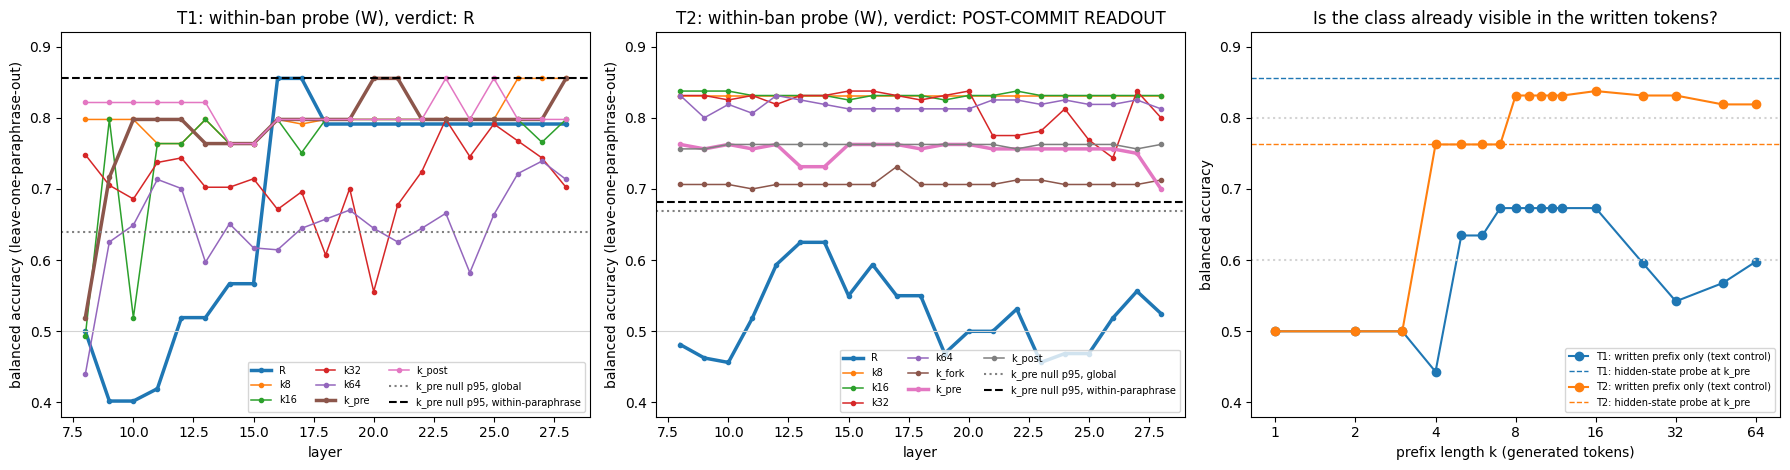

In [18]:
# W-probe balanced accuracy by layer per position (left, middle) and the written-text control (right)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, t in zip(axes[:2], ("T1", "T2")):
    W = loc["tasks"][t]["contrasts"]["W"]["positions"]
    for p, pr in W.items():
        ax.plot(pr["layers"], np.array(pr["BA"], dtype=float), marker=".", lw=2.5 if p in ("R", "k_pre") else 1.1, label=p)
    ax.axhline(W["k_pre"]["layer_max_null_global_p95"], color="grey", ls=":", label="k_pre null p95, global")
    ax.axhline(W["k_pre"]["layer_max_null_within_p95"], color="black", ls="--", label="k_pre null p95, within-paraphrase")
    ax.axhline(0.5, color="lightgrey", lw=0.8)
    ax.set(title=f"{t}: within-ban probe (W), verdict: {lsec['tasks'][t]['qualified_verdict'].split(' (')[0]}",
           xlabel="layer", ylabel="balanced accuracy (leave-one-paraphrase-out)", ylim=(0.38, 0.92))
    ax.legend(fontsize=7, ncol=3, loc="lower right")
ax = axes[2]
for t in ("T1", "T2"):
    curve = lsec["tasks"][t]["text_locus_curve"]
    ks = sorted(int(k) for k in curve)
    line, = ax.plot(ks, [curve[str(k)] for k in ks], marker="o", label=f"{t}: written prefix only (text control)")
    ax.axhline(lsec["tasks"][t]["layer_max_table"]["k_pre"]["layer_max_BA"], color=line.get_color(), ls="--", lw=1,
               label=f"{t}: hidden-state probe at k_pre")
for y in (0.6, 0.8):
    ax.axhline(y, color="lightgrey", ls=":")
ax.set_xscale("log", base=2)
ax.set_xticks([1, 2, 4, 8, 16, 32, 64], [1, 2, 4, 8, 16, 32, 64])
ax.set(title="Is the class already visible in the written tokens?", xlabel="prefix length k (generated tokens)",
       ylabel="balanced accuracy", ylim=(0.38, 0.92))
ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

## Results 3: the activation space itself, and the centroid geometry (0a, 0b)

**Top row.** These are the actual saved residual-stream states of Qwen3-8B, 300 per task, projected onto their first two principal components (the PCA views computed by `locus.py`).
- Grey: baseline rows.
- Blue squares: ban rows that still wrote the default.
- Orange triangles: ban rows that wrote the substitute.

At R, ban prompts separate from baseline prompts, but the two ban outcomes overlap. At k_pre, PC1 tracks the prefix already written, as the text control predicts. On T2, 11 of the 20 Dijkstra-under-ban rows sit in the baseline cluster, against only 2 of the 80 BF_SPFA rows. Many states coincide exactly, since the same prompt and the same prefix give the same state.

**Bottom row.** This is the geometry robustness sweep of `geometry.py`.
- The heatmaps show the share of 1000 paraphrase subsamples in which a given survivor is the one nearest the default's centroid.
- The lines show the full-data graph-geodesic distances from the default's centroid at k = 10.

On T2, Floyd-Warshall, not the realised substitute BF_SPFA, is nearest at every layer and every k. On T1, DFS is nearest from layer 25 on. At layer 24 the full-data order flips to UNIT_DIJKSTRA first, and DFS wins only 52 to 60% of the subsamples.

The audit's verdict: *consistent with geodesic proximity and with typicality; not separated on these events*.

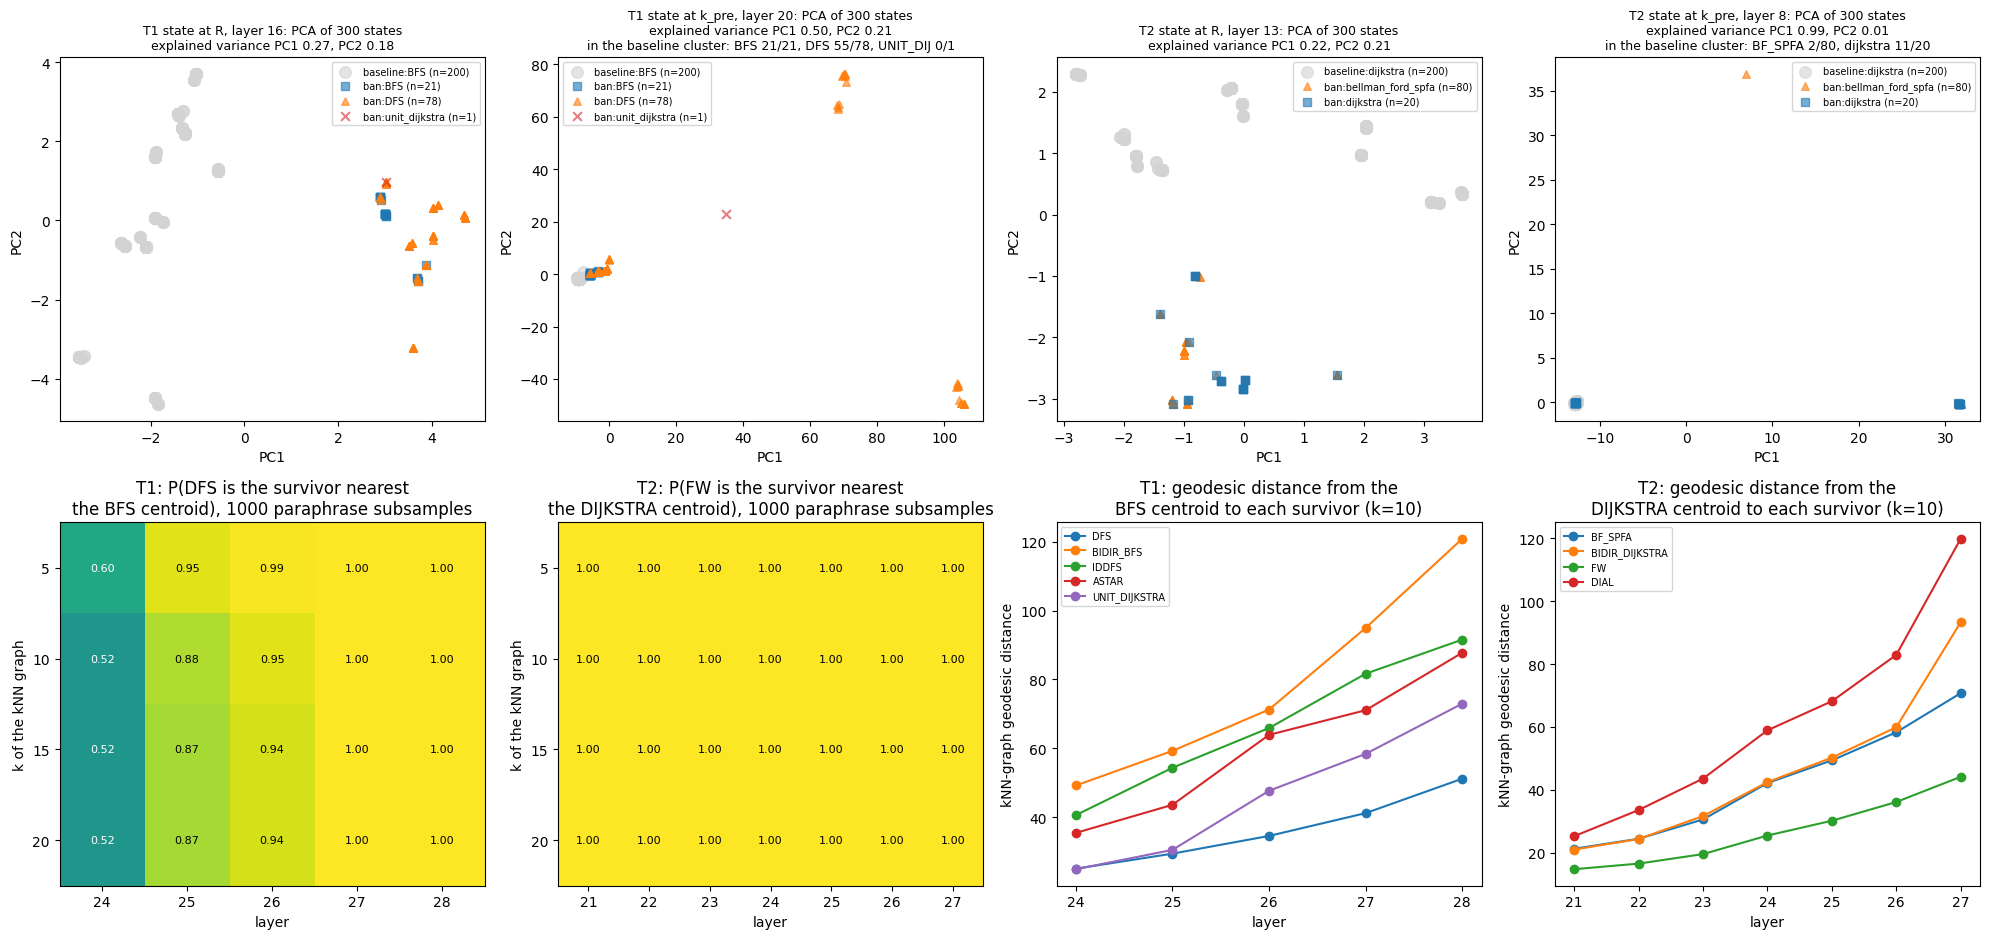

In [19]:
# Top: PCA views of the saved Qwen3-8B states (locus.py); bottom: geometry robustness grid (geometry.py)
STYLE = {"baseline": ("lightgrey", "o", 70), "ban:BFS": ("tab:blue", "s", 28), "ban:dijkstra": ("tab:blue", "s", 28),
         "ban:DFS": ("tab:orange", "^", 30), "ban:bellman_ford_spfa": ("tab:orange", "^", 30)}
SHORT = {"bellman_ford_spfa": "BF_SPFA", "unit_dijkstra": "UNIT_DIJ"}
fig, axes = plt.subplots(2, 4, figsize=(20, 9.5))
for ax, (t, name) in zip(axes[0], [("T1", "R|L16"), ("T1", "k_pre|L20"), ("T2", "R|L13"), ("T2", "k_pre|L8")]):
    V = loc["tasks"][t]["pca_views"][name]
    x, y, tag = np.array(V["x"]), np.array(V["y"]), np.array(V["tag"])
    for g in sorted(set(tag), key=lambda g: (g.startswith("ban"), g)):
        m = tag == g
        color, marker, size = STYLE.get(g.split(":")[0] if g.startswith("baseline") else g, ("tab:red", "x", 40))
        ax.scatter(x[m], y[m], s=size, c=color, marker=marker, alpha=0.6, label=f"{g} (n={m.sum()})")
    title = (f"{t} state at {V['position']}, layer {V['layer']}: PCA of {len(tag)} states\n"
             f"explained variance PC1 {V['explained'][0]:.2f}, PC2 {V['explained'][1]:.2f}")
    if V["position"] == "k_pre":  # how many within-ban rows of each class sit in the baseline cluster along PC1?
        base = np.array([g.startswith("baseline") for g in tag])
        near = np.abs(x - x[base].mean()) < np.abs(x - x[~base].mean())
        title += "\nin the baseline cluster: " + ", ".join(
            f"{SHORT.get(g.split(':')[1], g.split(':')[1])} {int(near[tag == g].sum())}/{int((tag == g).sum())}"
            for g in sorted(set(tag[~base])))
    ax.set_title(title, fontsize=9)
    ax.set(xlabel="PC1", ylabel="PC2")
    ax.legend(fontsize=7)
grid = pd.DataFrame(geo["grid"])
forced = grid[grid.kind == "forced"]
for ax, (t, col, default) in zip(axes[1, :2], [("t1", "P_DFS_nearest", "BFS"), ("t2", "P_FW_nearest", "DIJKSTRA")]):
    h = forced[forced.task == t].pivot(index="k", columns="layer", values=col)
    ax.imshow(h.values, vmin=0, vmax=1, cmap="viridis", aspect="auto")
    ax.set_xticks(range(h.shape[1]), h.columns)
    ax.set_yticks(range(h.shape[0]), h.index)
    for i in range(h.shape[0]):
        for j in range(h.shape[1]):
            ax.text(j, i, f"{h.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if h.values[i, j] < 0.6 else "black")
    ax.set(title=f"{t.upper()}: P({col[2:-8]} is the survivor nearest\nthe {default} centroid), 1000 paraphrase subsamples",
           xlabel="layer", ylabel="k of the kNN graph")
for ax, (t, default) in zip(axes[1, 2:], [("t1", "BFS"), ("t2", "DIJKSTRA")]):
    sub = forced[(forced.task == t) & (forced.k == 10)].sort_values("layer")
    dist = pd.DataFrame(list(sub.full_distances), index=sub.layer.values)
    for alg in dist.columns:
        ax.plot(dist.index, dist[alg], marker="o", label=alg)
    ax.set_xticks(dist.index)
    ax.set(title=f"{t.upper()}: geodesic distance from the\n{default} centroid to each survivor (k=10)", xlabel="layer",
           ylabel="kNN-graph geodesic distance")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## Results 4: what replaces a banned default, and do diversity knobs help? (0c, 0d)

**Left and middle panels.** These show the algorithm mix among *correct* programs for the curated perturbation rows.
- **Bans substitute rather than subtract.** Banning the default does not spread the programs over the catalogue. It moves them to one runner-up: DFS on T1 and BF_SPFA on T2.
- **Sham bans** (bans of algorithms the model rarely writes) leave the default on top among correct programs. Among *attempted* programs, the audit's sham-ban check (0g) still finds two promotions, both of the runner-up: the IDDFS ban promotes DFS by 12 points, and the Floyd-Warshall ban promotes BF_SPFA by 23 points.
- **Most other knobs leave the default in place.** This holds for temperature 0.3 vs 1.3 at top-k 10, for the word and entropy seeds, and for the "creative" and "fully novel" instructions.
- **Two kinds of exception.** The T2 semantic seed shifts about 66 points toward BF_SPFA. Some named-mode cues (`mention:`) pull in the algorithm they name: A* in 24 of 41 correct T1 programs, and Floyd-Warshall in 43 of 44 on T2.

**Right panel.** This places every knob of the knob table on diversity vs pass cost. No diversity knob or ban enters the target region. The T2 semantic seed comes closest, at Hill-1 1.93 for 7 points. Only two things exceed Hill-1 2:
- the gen-then-select ceiling, at 24 to 42 points of pass cost. Here the model first lists candidate algorithms, then one listed item is drawn at random and implemented.
- the named-mode cue `mention:astar_gbfs`, which recommends an algorithm rather than inventing one.

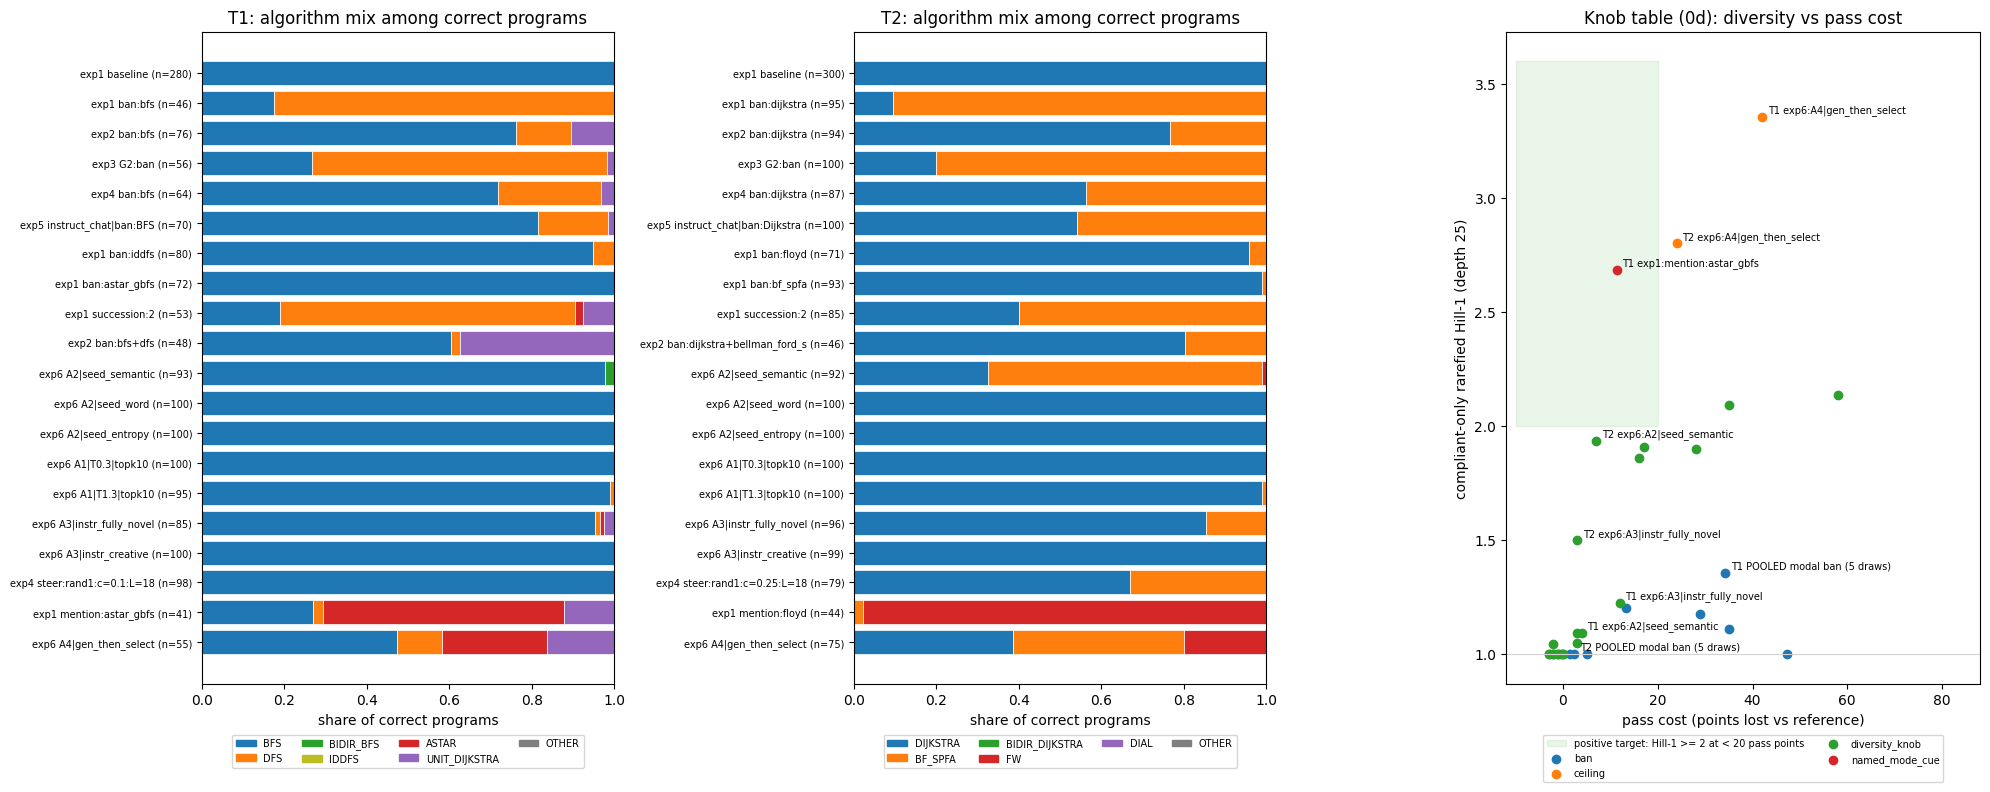

In [20]:
# Left/middle: algorithm mix among correct programs per perturbation row (0c); right: knob table (0d)
PALETTE = {"T1": {"BFS": "tab:blue", "DFS": "tab:orange", "BIDIR_BFS": "tab:green", "IDDFS": "tab:olive",
                  "ASTAR": "tab:red", "UNIT_DIJKSTRA": "tab:purple", "OTHER": "tab:gray"},
           "T2": {"DIJKSTRA": "tab:blue", "BF_SPFA": "tab:orange", "BIDIR_DIJKSTRA": "tab:green", "FW": "tab:red",
                  "DIAL": "tab:purple", "OTHER": "tab:gray"}}
fig, axes = plt.subplots(1, 3, figsize=(20, 8), gridspec_kw={"width_ratios": [1, 1, 1.15]})
for ax, t in zip(axes[:2], ("T1", "T2")):
    rows = pt[pt.task == t].reset_index(drop=True)
    for i, r in rows.iterrows():
        comp = json.loads(r.composition_correct) if isinstance(r.composition_correct, str) else {}
        tot, left = sum(comp.values()), 0.0
        for alg in sorted(comp, key=lambda a: list(PALETTE[t]).index(a) if a in PALETTE[t] else 99):
            ax.barh(i, comp[alg] / tot, left=left, color=PALETTE[t].get(alg, "black"), edgecolor="white", lw=0.5)
            left += comp[alg] / tot
    ax.set_yticks(range(len(rows)), [f"{r.experiment} {r.condition}"[:32] + f" (n={r.correct})" for r in rows.itertuples()],
                  fontsize=7)
    ax.invert_yaxis()
    ax.set(title=f"{t}: algorithm mix among correct programs", xlabel="share of correct programs", xlim=(0, 1))
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in PALETTE[t].values()], list(PALETTE[t]), fontsize=7, ncol=4,
              loc="upper center", bbox_to_anchor=(0.5, -0.07))
ax = axes[2]
ax.fill_between([-10, 20], 2, 3.6, color="tab:green", alpha=0.1, label="positive target: Hill-1 >= 2 at < 20 pass points")
for cls, g in kt.groupby("knob_class"):
    ax.scatter(g.pass_points, g.hill1_rarefied, s=36, label=cls)
for r in kt.itertuples():
    if np.isfinite(r.hill1_rarefied) and (r.knob_class in ("ceiling", "named_mode_cue")
                                          or r.type in ("seed_semantic", "ban_single_pooled", "instr_novel2000")):
        ax.annotate(f"{r.task} {r.knob}", (r.pass_points, r.hill1_rarefied), fontsize=7, xytext=(4, 3),
                    textcoords="offset points")
ax.axhline(1, color="lightgrey", lw=0.8)
ax.set_xlim(min(-12, kt.pass_points.min() - 2), kt.pass_points.max() + 30)
ax.set(title="Knob table (0d): diversity vs pass cost", xlabel="pass cost (points lost vs reference)",
       ylabel="compliant-only rarefied Hill-1 (depth 25)")
ax.legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.07))
plt.tight_layout()
plt.show()

## Takeaways, and how to run the full audit

**Takeaways**

- **Temperature is not the creativity knob here.** In all 32 temperature rows of the full perturbation table (T 0.3 to 1.3, top-k 10 or top-p 0.95), the default keeps at least 98.9% of correct programs.
- **Prompt bans substitute rather than subtract.** Removing the default hands most compliant programs to one runner-up, in every draw: DFS replaces BFS (116 of 128), and BF_SPFA replaces Dijkstra (272 of 272).
- **Context seeds and novelty instructions barely move the choice.** The one large shift, the T2 semantic seed, also lands on the runner-up. No diversity knob or ban reaches Hill-1 >= 2 within 20 points of pass cost.
- **Inside the model, the outcome is readable too late.** On T1 it is readable before generation, but only at the level of the paraphrase. On T2 it is readable only once the first import line has been written. The deciding token is generated index 3, and the states that emit it (k = 1..3) were not saved, so they are the next round's extraction target.
- **The geometric-neighbour account does not survive resampling on T2.** Floyd-Warshall, not BF_SPFA, is nearest the Dijkstra centroid. On T1, DFS is nearest only from layer 25 on.

**Run the full audit.** Do this from the artifact's own folder, not from this demo:

```bash
uv venv .venv --python=3.12
uv pip install --python .venv/bin/python -r requirements.txt
export ITER1_ROOT=<folder holding gen_art_experiment_1..6>
.venv/bin/python eval.py --rerun
```

The run takes about 16 minutes with a GPU. It rebuilds every stage output, including the full tables of 249, 183 and 903 rows. The same assembly code shown above then reproduces all 80 published metrics.